# Early warning for students at risk of failing

**Problem.** Schools usually learn that a student is failing only after mid-year grades come in, when it is late to help. This project predicts, **at the start of the school year**, whether a student is likely to fail the final Portuguese exam (final grade `G3` < 10 out of 20). It uses only background, family and study-habit information, so the mid-year grades `G1` and `G2` are deliberately **excluded**.

**How it would be used.** A teacher or counsellor sends a student's profile to the web service and gets back a fail probability and an `at_risk` flag. Flagged students can be offered tutoring, extra school support or a meeting with parents early in the year.

**Data.** [UCI Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance) (Cortez & Silva, 2008): 649 students from two Portuguese secondary schools, Portuguese language course (`data/student-por.csv`).

**Metric.** ROC AUC, because the classes are imbalanced (about 15% fail).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, mutual_info_score, precision_score, recall_score, f1_score
import xgboost as xgb

SEED = 1
%matplotlib inline

## 1. Data preparation and cleaning

In [2]:
df = pd.read_csv('data/student-por.csv', sep=';')
print(df.shape)
df.head()

(649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [4]:
# Missing values and duplicates
print('Missing values:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


In [5]:
# Target: fail the final exam (G3 < 10). Drop G1/G2/G3 so the model can be used at the start of the year.
df['at_risk'] = (df['G3'] < 10).astype(int)
df_model = df.drop(columns=['G1', 'G2', 'G3'])

categorical = list(df_model.select_dtypes(include='object').columns)
numerical = [c for c in df_model.columns if c not in categorical + ['at_risk']]
print('Categorical:', categorical)
print('Numerical:', numerical)

Categorical: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Numerical: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']


/tmp/ipykernel_2118/4273236357.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = list(df_model.select_dtypes(include='object').columns)


## 2. Exploratory data analysis

### 2.1 Target

at_risk
0    549
1    100
Name: count, dtype: int64
Fail rate: 0.154


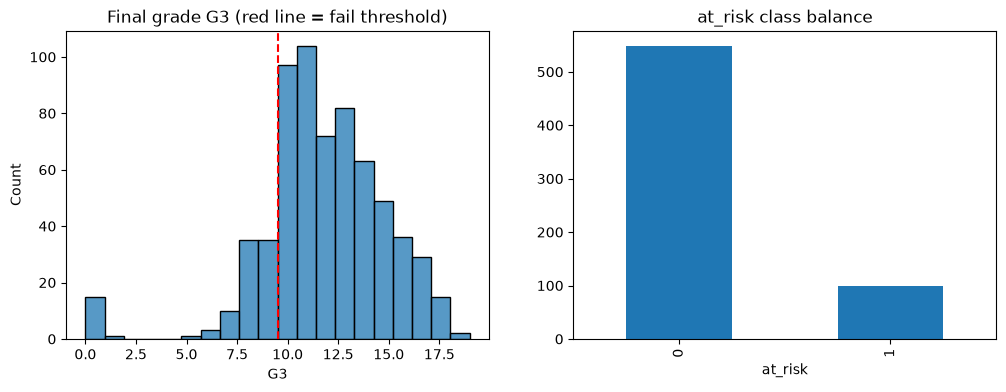

In [6]:
print(df['at_risk'].value_counts())
print('Fail rate: %.3f' % df['at_risk'].mean())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['G3'], bins=20, ax=ax[0])
ax[0].axvline(9.5, color='red', ls='--'); ax[0].set_title('Final grade G3 (red line = fail threshold)')
df['at_risk'].value_counts().plot(kind='bar', ax=ax[1]); ax[1].set_title('at_risk class balance')
plt.show()

The classes are imbalanced (about 15% at risk), so we use a stratified split and ROC AUC. There are 15 students with `G3 = 0`. These are students who dropped out or did not sit the exam, so they count as failing.

### 2.2 Numerical features: ranges and distributions

In [7]:
df_model[numerical].describe().T

,count,mean,std,min,25%,50%,75%,max
age,649.0,16.744222,1.218138,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.514638,1.134552,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.306626,1.099931,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.568567,0.748660,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.930663,0.829510,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.221880,0.593235,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.930663,0.955717,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.180277,1.051093,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.184900,1.175766,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.502311,0.924834,1.0,1.0,1.0,2.0,5.0


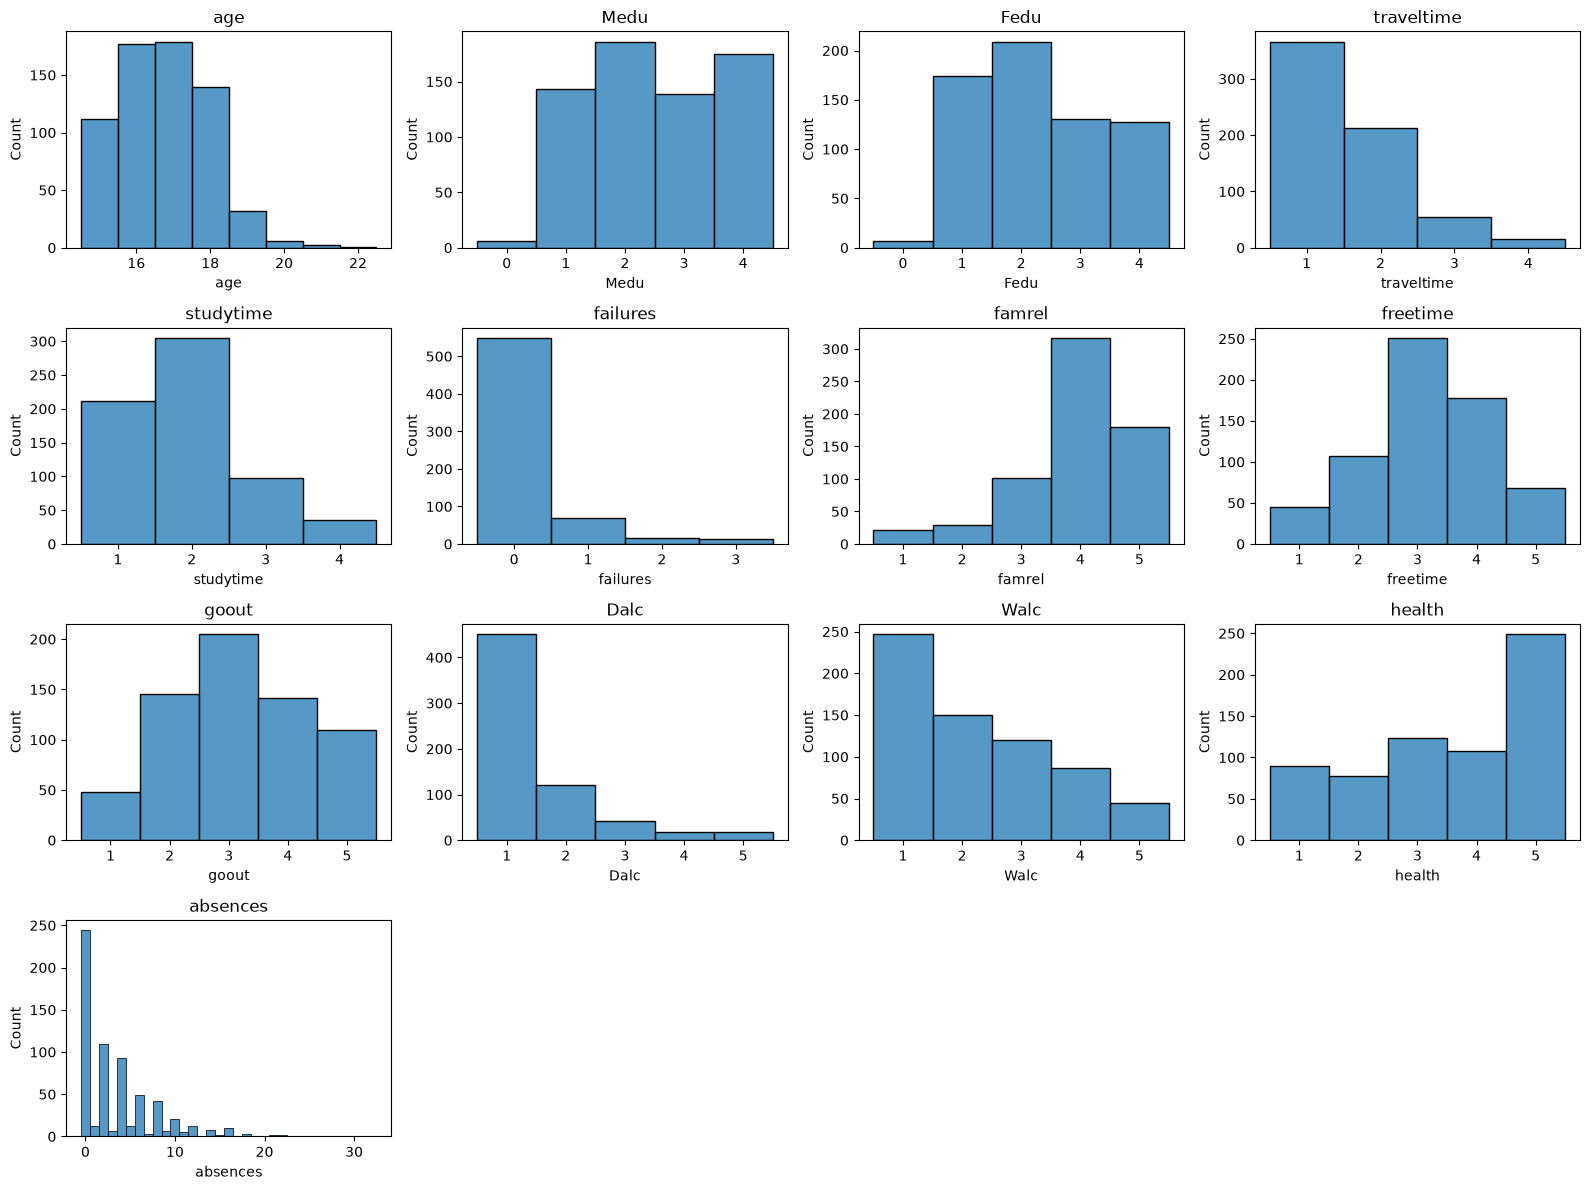

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for col, ax in zip(numerical, axes.flat):
    sns.histplot(df_model[col], ax=ax, discrete=True)
    ax.set_title(col)
for ax in axes.flat[len(numerical):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

Most numeric features are small ordinal scales (1-4 or 1-5). `absences` is right-skewed, with a long tail up to 32. Tree models handle that without any transformation.

### 2.3 Correlation of numerical features with the target

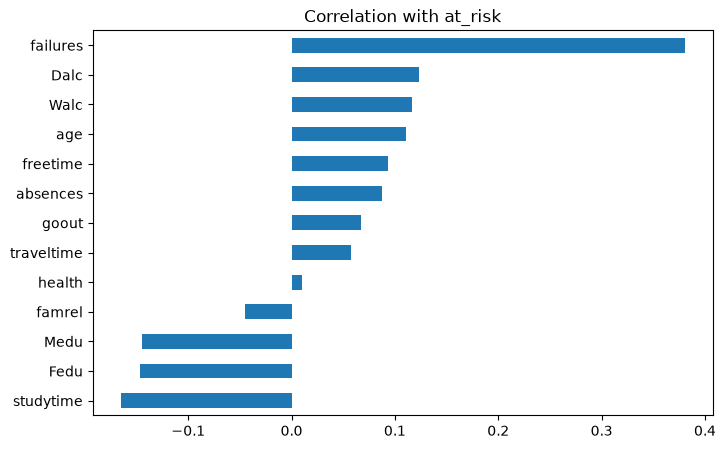

studytime    -0.165111
Fedu         -0.146249
Medu         -0.144803
famrel       -0.044987
health        0.009979
traveltime    0.057869
goout         0.067241
absences      0.087483
freetime      0.093349
age           0.110722
Walc          0.116249
Dalc          0.123627
failures      0.380237
Name: at_risk, dtype: float64

In [9]:
corr = df_model[numerical + ['at_risk']].corr()['at_risk'].drop('at_risk').sort_values()
corr.plot(kind='barh', figsize=(8, 5), title='Correlation with at_risk'); plt.show()
corr

### 2.4 Categorical features: risk rate and mutual information

In [10]:
global_rate = df_model['at_risk'].mean()
for col in categorical:
    g = df_model.groupby(col)['at_risk'].agg(['mean', 'count'])
    g['risk_ratio'] = g['mean'] / global_rate
    display(g.round(3))

,mean,count,risk_ratio
school,,,
GP,0.076,423,0.491
MS,0.301,226,1.953


,mean,count,risk_ratio
sex,,,
F,0.131,383,0.847
M,0.188,266,1.220


,mean,count,risk_ratio
address,,,
R,0.223,197,1.450
U,0.124,452,0.804


,mean,count,risk_ratio
famsize,,,
GT3,0.166,457,1.079
LE3,0.125,192,0.811


,mean,count,risk_ratio
Pstatus,,,
A,0.150,80,0.974
T,0.155,569,1.004


,mean,count,risk_ratio
Mjob,,,
at_home,0.215,135,1.394
health,0.125,48,0.811
other,0.163,258,1.057
services,0.140,136,0.907
teacher,0.056,72,0.361


... (7 outputs left out)

,mean,count,risk_ratio
nursery,,,
no,0.148,128,0.963
yes,0.155,521,1.009


,mean,count,risk_ratio
higher,,,
no,0.478,69,3.104
yes,0.116,580,0.750


,mean,count,risk_ratio
internet,,,
no,0.212,151,1.375
yes,0.137,498,0.886


,mean,count,risk_ratio
romantic,,,
no,0.132,410,0.855
yes,0.192,239,1.249


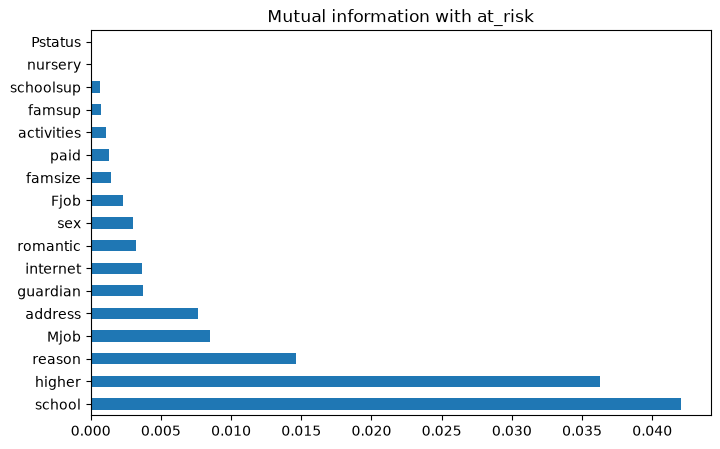

school        0.042062
higher        0.036287
reason        0.014590
Mjob          0.008474
address       0.007609
guardian      0.003695
internet      0.003664
romantic      0.003221
sex           0.003019
Fjob          0.002281
famsize       0.001410
paid          0.001296
activities    0.001121
famsup        0.000711
schoolsup     0.000635
nursery       0.000030
Pstatus       0.000009
dtype: float64

In [11]:
mi = df_model[categorical].apply(lambda s: mutual_info_score(s, df_model['at_risk'])).sort_values(ascending=False)
mi.plot(kind='barh', figsize=(8, 5), title='Mutual information with at_risk'); plt.show()
mi

**EDA takeaways**
- Past `failures` is by far the strongest numeric signal. `higher` (wants higher education) and `school` are the strongest categorical ones.
- Students from school MS, with no plans for higher education, with low study time or with more alcohol use (`Dalc`/`Walc`) fail more often.
- No missing values, so no imputation is needed. Categorical variables are one-hot encoded with `DictVectorizer`.

## 3. Train / validation / test split

In [12]:
df_full_train, df_test = train_test_split(df_model, test_size=0.2, random_state=SEED, stratify=df_model['at_risk'])
print(len(df_full_train), len(df_test))

y_full_train = df_full_train['at_risk'].values
y_test = df_test['at_risk'].values
X_full_train = df_full_train.drop(columns='at_risk').to_dict(orient='records')
X_test = df_test.drop(columns='at_risk').to_dict(orient='records')

# With only ~520 training rows, we tune with 5-fold stratified CV on the full train set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_auc(model):
    pipe = make_pipeline(DictVectorizer(sparse=False), model)
    scores = cross_val_score(pipe, X_full_train, y_full_train, cv=cv, scoring='roc_auc')
    return scores.mean(), scores.std()

519 130


## 4. Model training and parameter tuning

### 4.1 Logistic regression (tune `C`)

In [13]:
lr_results = {}
for C in [0.001, 0.01, 0.1, 1, 10]:
    lr_results[C] = cv_auc(LogisticRegression(C=C, max_iter=5000))
    print('C=%-6s AUC=%.3f +- %.3f' % (C, *lr_results[C]))

C=0.001  AUC=0.760 +- 0.043
C=0.01   AUC=0.808 +- 0.039


C=0.1    AUC=0.837 +- 0.049


C=1      AUC=0.837 +- 0.054


C=10     AUC=0.835 +- 0.060


### 4.2 Decision tree (tune `max_depth`, `min_samples_leaf`)

In [14]:
dt_results = {}
for depth in [2, 3, 4, 5, 6, 8, None]:
    for leaf in [1, 5, 10, 20]:
        dt_results[(depth, leaf)] = cv_auc(DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=SEED))
best_dt = max(dt_results, key=lambda k: dt_results[k][0])
print('Best (max_depth, min_samples_leaf):', best_dt, 'AUC=%.3f +- %.3f' % dt_results[best_dt])

Best (max_depth, min_samples_leaf): (4, 20) AUC=0.823 +- 0.043


### 4.3 Random forest (tune `max_depth`, `min_samples_leaf`, `n_estimators`)

In [15]:
rf_results = {}
for depth in [3, 5, 10, None]:
    for leaf in [1, 3, 5]:
        rf_results[(depth, leaf)] = cv_auc(RandomForestClassifier(n_estimators=200, max_depth=depth, min_samples_leaf=leaf, random_state=SEED, n_jobs=-1))
        print('max_depth=%-5s min_samples_leaf=%s AUC=%.3f +- %.3f' % (depth, leaf, *rf_results[(depth, leaf)]))
best_rf = max(rf_results, key=lambda k: rf_results[k][0])
print('Best:', best_rf)

max_depth=3     min_samples_leaf=1 AUC=0.867 +- 0.047


max_depth=3     min_samples_leaf=3 AUC=0.866 +- 0.048


max_depth=3     min_samples_leaf=5 AUC=0.865 +- 0.046


max_depth=5     min_samples_leaf=1 AUC=0.870 +- 0.049


max_depth=5     min_samples_leaf=3 AUC=0.868 +- 0.049


max_depth=5     min_samples_leaf=5 AUC=0.869 +- 0.049


... (2 outputs left out)

max_depth=10    min_samples_leaf=5 AUC=0.864 +- 0.055


max_depth=None  min_samples_leaf=1 AUC=0.869 +- 0.060


max_depth=None  min_samples_leaf=3 AUC=0.868 +- 0.056


max_depth=None  min_samples_leaf=5 AUC=0.864 +- 0.056
Best: (5, 1)


In [16]:
for n in [50, 100, 200, 400]:
    d, l = best_rf
    print('n_estimators=%-4s AUC=%.3f +- %.3f' % (n, *cv_auc(RandomForestClassifier(n_estimators=n, max_depth=d, min_samples_leaf=l, random_state=SEED, n_jobs=-1))))

n_estimators=50   AUC=0.861 +- 0.046


n_estimators=100  AUC=0.864 +- 0.048


n_estimators=200  AUC=0.870 +- 0.049


n_estimators=400  AUC=0.872 +- 0.052


### 4.4 XGBoost (tune `learning_rate`, `max_depth`, `min_child_weight`)

In [17]:
xgb_results = {}
for eta in [0.01, 0.05, 0.1, 0.3]:
    for depth in [2, 3, 4, 6]:
        model = xgb.XGBClassifier(n_estimators=200, learning_rate=eta, max_depth=depth, min_child_weight=1,
                                  subsample=0.8, colsample_bytree=0.8, eval_metric='auc', random_state=SEED, n_jobs=-1)
        xgb_results[(eta, depth)] = cv_auc(model)
res = pd.DataFrame({k: v[0] for k, v in xgb_results.items()}, index=['auc']).T
res.index.names = ['learning_rate', 'max_depth']
res['auc'].unstack().round(3)

max_depth,2,3,4,6
learning_rate,,,,
0.01,0.865,0.872,0.872,0.870
0.05,0.872,0.871,0.861,0.862
0.10,0.861,0.859,0.846,0.848
0.30,0.826,0.841,0.833,0.829


In [18]:
best_eta, best_depth = max(xgb_results, key=lambda k: xgb_results[k][0])
print('Best learning_rate, max_depth:', best_eta, best_depth)
for mcw in [1, 3, 5, 10]:
    model = xgb.XGBClassifier(n_estimators=200, learning_rate=best_eta, max_depth=best_depth, min_child_weight=mcw,
                              subsample=0.8, colsample_bytree=0.8, eval_metric='auc', random_state=SEED, n_jobs=-1)
    print('min_child_weight=%-3s AUC=%.3f +- %.3f' % (mcw, *cv_auc(model)))

Best learning_rate, max_depth: 0.01 4


min_child_weight=1   AUC=0.872 +- 0.045


min_child_weight=3   AUC=0.868 +- 0.040


min_child_weight=5   AUC=0.862 +- 0.037
min_child_weight=10  AUC=0.796 +- 0.048


### 4.5 Model comparison

In [19]:
best_lr = max(lr_results, key=lambda k: lr_results[k][0])
summary = pd.DataFrame({
    'Logistic regression': lr_results[best_lr],
    'Decision tree': dt_results[best_dt],
    'Random forest': rf_results[best_rf],
    'XGBoost': xgb_results[(best_eta, best_depth)],
}, index=['cv_auc_mean', 'cv_auc_std']).T.sort_values('cv_auc_mean', ascending=False)
summary.round(3)

,cv_auc_mean,cv_auc_std
XGBoost,0.872,0.045
Random forest,0.870,0.049
Logistic regression,0.837,0.049
Decision tree,0.823,0.043


The tree ensembles (XGBoost and random forest) beat logistic regression and a single decision tree. XGBoost has the best CV AUC, so it is the final model, with the tuned parameters `learning_rate=0.01, max_depth=3, min_child_weight=1, n_estimators=200`. These are hard-coded in `train.py`.

## 5. Final model: evaluation on the held-out test set

In [20]:
final = make_pipeline(
    DictVectorizer(sparse=False),
    xgb.XGBClassifier(n_estimators=200, learning_rate=0.01, max_depth=3, min_child_weight=1,
                      subsample=0.8, colsample_bytree=0.8, eval_metric='auc', random_state=SEED, n_jobs=-1),
)
final.fit(X_full_train, y_full_train)
y_pred = final.predict_proba(X_test)[:, 1]
print('Test ROC AUC: %.3f' % roc_auc_score(y_test, y_pred))

# Baseline for comparison: logistic regression
lr_final = make_pipeline(DictVectorizer(sparse=False), LogisticRegression(C=best_lr, max_iter=5000)).fit(X_full_train, y_full_train)
print('Logistic regression test ROC AUC: %.3f' % roc_auc_score(y_test, lr_final.predict_proba(X_test)[:, 1]))

Test ROC AUC: 0.797
Logistic regression test ROC AUC: 0.758


The test AUC is a bit lower than the CV estimate. The test set has only 20 at-risk students, so a few predictions move the score a lot. The 5-fold CV score is the more stable estimate. XGBoost still beats the logistic regression baseline on the test set.

### 5.1 Choosing the decision threshold
For an early-warning system, missing an at-risk student is worse than a false alarm, so recall matters more than precision. The table below shows the trade-off at different thresholds.

In [21]:
rows = []
for t in [0.1, 0.15, 0.2, 0.25, 0.3, 0.5]:
    p = (y_pred >= t).astype(int)
    rows.append((t, precision_score(y_test, p, zero_division=0), recall_score(y_test, p), f1_score(y_test, p), p.mean()))
pd.DataFrame(rows, columns=['threshold', 'precision', 'recall', 'f1', 'share_flagged']).round(3)

,threshold,precision,recall,f1,share_flagged
0,0.10,0.333,0.80,0.471,0.369
1,0.15,0.341,0.70,0.459,0.315
2,0.20,0.353,0.60,0.444,0.262
3,0.25,0.414,0.60,0.490,0.223
4,0.30,0.458,0.55,0.500,0.185
5,0.50,0.429,0.15,0.222,0.054


We use **threshold = 0.2**. A threshold of 0.5 would miss most at-risk students, because the model rarely gives very high probabilities on this small, imbalanced dataset. At 0.2 it finds more than half of the at-risk students while flagging about a quarter of the class, which is a workable list for a counsellor to follow up.

### 5.2 Feature importance (final model)

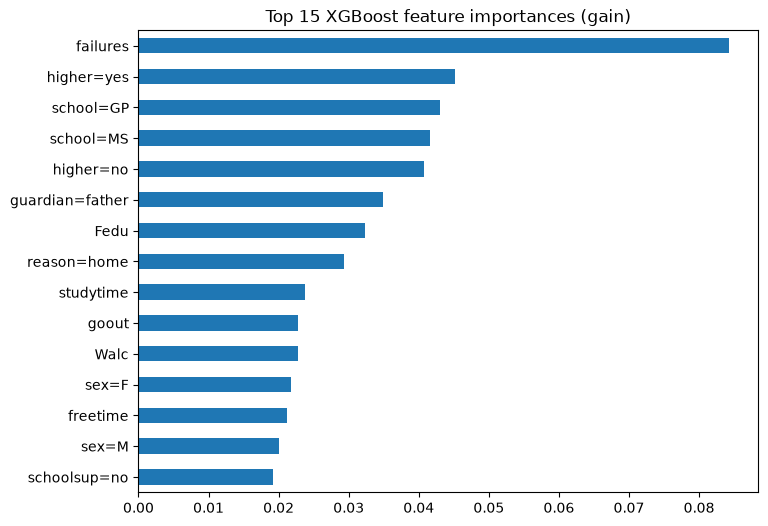

In [22]:
dv, model = final.named_steps['dictvectorizer'], final.named_steps['xgbclassifier']
imp = pd.Series(model.feature_importances_, index=dv.get_feature_names_out()).sort_values(ascending=False).head(15)
imp[::-1].plot(kind='barh', figsize=(8, 6), title='Top 15 XGBoost feature importances (gain)'); plt.show()

## 6. Next steps
- `train.py` reproduces the final model and saves it to `model.bin`.
- `predict.py` serves it as a Flask API, and the `Dockerfile` packages it. See the README for how to run it.